In [16]:
from optiland import optic, physical_apertures
import optiland.backend as be
from optiland import analysis
from optiland import wavefront
from optiland.psf import MMDFTPSF, FFTPSF
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import numpy as np
from torch.special import bessel_j1
from torch.special import bessel_j0
from dynesty import plotting as dyplot
from gluonts.torch.distributions import TruncatedNormal as truncnorm
import torch
import corner
plt.rcParams['figure.figsize'] = (20,10)

In [2]:
be.set_backend("torch")
be.grad_mode.disable()
be.set_precision("float64")

In [3]:
torch.set_default_dtype(torch.float64)

In [5]:
def bessel_j2(x):
    return 2*bessel_j1(x)/x - bessel_j0(x)
def bessel_j3(x):
    return 2*2*bessel_j2(x)/x - bessel_j1(x)
def bessel_j4(x):
    return 2*3*bessel_j3(x)/x - bessel_j2(x)
def bessel_j5(x):
    return 2*4*bessel_j4(x)/x - bessel_j3(x)
def bessel_j6(x):
    return 2*5*bessel_j5(x)/x - bessel_j4(x)
def bessel_j7(x):
    return 2*6*bessel_j6(x)/x - bessel_j5(x)
def bessel_j8(x):
    return 2*7*bessel_j7(x)/x - bessel_j6(x)
def bessel_j9(x):
    return 2*8*bessel_j8(x)/x - bessel_j7(x)
def bessel_j10(x):
    return 2*9*bessel_j9(x)/x - bessel_j8(x)
def bessel_j11(x):
    return 2*10*bessel_j10(x)/x - bessel_j9(x)
def bessel_j12(x):
    return 2*11*bessel_j11(x)/x - bessel_j10(x)
def bessel_j13(x):
    return 2*12*bessel_j12(x)/x - bessel_j11(x)
def bessel_j14(x):
    return 2*13*bessel_j13(x)/x - bessel_j12(x)
def bessel_j15(x):
    return 2*14*bessel_j14(x)/x - bessel_j13(x)

def bessel_jv(n, x):
    if n == 0:
        return bessel_j0(x)
    elif n == 1:
        return bessel_j1(x)
    elif n == 2:
        return bessel_j2(x)
    elif n == 3:
        return bessel_j3(x)
    elif n == 4:
        return bessel_j4(x)
    elif n == 5:
        return bessel_j5(x)
    elif n == 6:
        return bessel_j6(x)
    elif n == 7:
        return bessel_j7(x)
    elif n == 8:
        return bessel_j8(x)
    elif n == 9:
        return bessel_j9(x)
    elif n == 10:
        return bessel_j10(x)
    elif n == 11:
        return bessel_j11(x)
    elif n == 12:
        return bessel_j12(x)
    elif n == 13:
        return bessel_j13(x)
    elif n == 14:
        return bessel_j14(x)
    elif n == 15:
        return bessel_j15(x)
    else:
        raise ValueError("n must be an integer between 0 and 15")

In [6]:
def _is_odd(integer):

    return integer & 1

def noll_indices(j):

    if j < 1:
        raise ValueError("Zernike index j must be a positive integer.")

    # from i, compute m and n
    # I'm not sure if there is an easier/cleaner algorithm or not.
    # This seems semi-complicated to me...

    # figure out which row of the triangle we're in (easy):
    n = int(torch.ceil((-1 + torch.sqrt(torch.tensor(1 + 8 * j))) / 2) - 1)
    if n == 0:
        m = 0
    else:
        nprev = (n + 1) * (n + 2) / 2  # figure out which entry in the row (harder)
        # The rule is that the even Z obtain even indices j, the odd Z odd indices j.
        # Within a given n, lower values of m obtain lower j.

        resid = int(j - nprev - 1)

        if _is_odd(j):
            sign = -1
        else:
            sign = 1

        if _is_odd(n):
            row_m = [1, 1]
        else:
            row_m = [0]

        for i in range(int(torch.floor(torch.tensor(n / 2.)))):
            row_m.append(row_m[-1] + 2)
            row_m.append(row_m[-1])

        m = row_m[resid] * sign

    return n, m

def circ_bessel(n, m, npix=128, rho=None, theta=None, outside=torch.nan, zero=7, **kwargs):
 
    if theta is None and rho is None:
        x = (torch.arange(npix, dtype=torch.float64) - (npix - 1) / 2.) / (zero)
        y = x
        xx, yy = torch.meshgrid(x, y)

        rho = torch.sqrt(xx ** 2 + yy ** 2)
        theta = torch.arctan2(yy, xx)
    elif (theta is None and rho is not None) or (theta is not None and rho is None):
        raise ValueError("If you provide either the `theta` or `rho` input array, you must "
                         "provide both of them.")
        
    if not torch.all(torch.asarray(rho.shape == theta.shape)):
        raise ValueError('The rho and theta arrays do not have consistent shape.')

    if m == 0:
        if n == 0:
            cb_result = bessel_j1(2*torch.pi*rho) * (1/rho)
        else:
            cb_result = -1**(n/2 + torch.abs(torch.tensor(m))) * bessel_jv(n+1, 2*torch.pi*rho) * (1/rho)
    elif m > 0:
        cb_result = -1**(n/2 + torch.abs(torch.tensor(m))) * bessel_jv(n+1, 2*torch.pi*rho) * (1/rho) * torch.cos(torch.abs(torch.tensor(m) * theta))
    else:
        cb_result = -1**(n/2 + torch.abs(torch.tensor(m))) * bessel_jv(n+1, 2*torch.pi*rho) * (1/rho) * torch.sin(torch.abs(torch.tensor(m) * theta))
    return torch.tensor(cb_result, dtype=torch.float64)


def circ_bessel1(j, **kwargs):

    n, m = noll_indices(j)
    return circ_bessel(n, m, **kwargs)

def basis_vectors(nterms=15, npix=256, rho=None, theta=None, **kwargs):
    
    if rho is not None and theta is not None:
        # both are required, but validated in circbessel1
        shape = rho.shape
        use_polar = True
    elif (theta is None and rho is not None) or (theta is not None and rho is None):
        raise ValueError("If you provide either the `theta` or `rho` input array, you must "
                         "provide both of them.")

    else:
        shape = (npix, npix)
        use_polar = False

    basis_output = torch.zeros((nterms,) + shape)

    if use_polar:
        for j in range(nterms):
            basis_output[j] = circ_bessel1(j+1, rho=rho, theta=theta, **kwargs)
    else:
        for j in range(nterms):
            basis_output[j] = circ_bessel1(j+1, npix=npix, **kwargs)
    return torch.tensor(basis_output, dtype=torch.float64)

def decompose_psf(psf, nterms=10, basis=basis_vectors, **kwargs):
    npix = psf.shape[0]
    basis_set = basis(nterms=nterms, npix=npix, outside=torch.nan, **kwargs)
    #basis_stack = np.stack(basis_set,  dim=0)  # shape: (nterms, npix, npix)
    psf_flat = psf.ravel()
    basis_flat = basis_set.reshape(nterms, -1).to(torch.float64)
    numerators = torch.matmul(basis_flat, psf_flat)
    denominators = torch.einsum('ij,ij->i', basis_flat, basis_flat)
    coeffs = numerators / denominators
    return torch.tensor(coeffs, dtype=torch.float64)

In [7]:
def telescopeCreation(WL,pdx,pdy,pdz,ptx,pty,sdx,sdy,sdz,stx,sty):

    K=1000 #mm to micron
    T = 3600
    #Pearl
    pearl = optic.Optic(name="Pearl")

    # set aperture
    pearl.set_aperture(aperture_type="EPD", value=6471.26)
    aperture1 = physical_apertures.RadialAperture(r_min=1380, r_max=6420) 
    a1 = physical_apertures.PolygonAperture(x=[1380, 6420, 6420, 1380], y=[300, 300, -300, -300])
    a2 = physical_apertures.PolygonAperture(x=[-3469, -2949, 260, -260], y=[5410, 5710, 150, -150])
    a3 = physical_apertures.PolygonAperture(x=[-3469, -2949, 260, -260], y=[-5410, -5710, -150, 150])
    a = aperture1 - a1 - a2 - a3

    # set fields
    pearl.set_field_type(field_type="angle")
    pearl.add_field(y=0.17)

    # set wavelengths
    pearl.add_wavelength(value=WL)

    # add surfaces
    pearl.add_surface(index=0, radius=be.inf, thickness=be.inf)

    pearl.add_surface(
        index=1,
        radius=-16256,
        thickness=-7400.005+pdz/K,
        dx=pdx/K,
        dy=pdy/K,
        rx=ptx/T,
        ry=pty/T,
        conic=-0.9953569,
        material="mirror",
        aperture=a,
        is_stop=True
    )
    pearl.add_surface(
        index=2,
        radius=-1660.575,
        thickness=7449.97+sdz/K,
        dx=sdx/K,
        dy=sdy/K,
        rx=stx/T,
        ry=sty/T,
        conic=-1.566503,
        material="mirror",
        #aperture=aperture2
    )
    pearl.add_surface(
        index=3,
        radius=-1830.517,
        thickness=-1033.62,
        conic=-0.718069,
        material="mirror",

    )

    pearl.add_surface(
        index=4,
        radius=be.inf,
        thickness=1220.34,
        material="mirror",

    )

    pearl.add_surface(index=5)

    return pearl

In [11]:
def genpsf(WL=0.650, pdx=0, pdy=0, pdz=0, ptx=0, pty=0, sdx=0, sdy=0, sdz=0, stx=0, sty=0, dterms=5):

    telescope = telescopeCreation(WL, pdx, pdy, pdz, ptx, pty, sdx, sdy, sdz, stx, sty)
    psf = FFTPSF(telescope, field=(0, 0.), wavelength=WL, grid_size=128)
    PSF = psf.psf
    r = decompose_psf(PSF, nterms=dterms, basis=basis_vectors)

    return r

In [12]:
#Truth

pdx_true = -3
pdy_true = 14
sdx_true = -18
sdy_true = 22

## PSF 
ct = genpsf(WL=0.65, pdx=pdx_true, pdy=pdy_true, sdx=sdx_true, sdy=sdy_true, dterms=10)

/opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/optiland/backend/torch_backend.py:246: UserWarning: Casting complex values to real discards the imaginary part (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/aten/src/ATen/native/Copy.cpp:309.)
  return x.to(device=get_device(), dtype=get_precision())
/opt/anaconda3/envs/spaceklip_new/lib/python3.11/site-packages/torch/functional.py:505: UserWarning: torch.meshgrid: in an upcoming release, it will be required to pass the indexing argument. (Triggered internally at /Users/runner/work/pytorch/pytorch/pytorch/aten/src/ATen/native/TensorShape.cpp:4319.)
  return _VF.meshgrid(tensors, **kwargs)  # type: ignore[attr-defined]
/var/folders/w0/w0glfprn2b7c2dkswb2qrm040000gn/T/ipykernel_27855/3322640369.py:68: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  return t

In [13]:
C = torch.tensor([[ 3.15977113e-05,  1.05929398e-07,  3.38687736e-07,
        -1.17108502e-05,  6.11042191e-07, -7.84187420e-07,
        -6.88435071e-07,  9.62967285e-07,  2.21757577e-07,
         1.22588916e-06],
       [ 1.05929398e-07,  1.16130787e-04,  1.11383722e-06,
         1.80318121e-07, -2.34423219e-07,  2.72356795e-06,
         2.32812403e-06,  2.79524483e-05, -6.76114108e-07,
         1.61332340e-06],
       [ 3.38687736e-07,  1.11383722e-06,  1.15833336e-04,
        -4.25835022e-08,  5.15797455e-07, -1.25443455e-06,
         3.14370115e-05, -5.80496165e-07,  3.58320515e-06,
         1.96151571e-06],
       [-1.17108502e-05,  1.80318121e-07, -4.25835022e-08,
         1.06229170e-04,  1.37679511e-06, -1.22034876e-06,
         3.11654301e-07,  3.71977634e-07, -3.56519060e-06,
        -8.43631623e-07],
       [ 6.11042191e-07, -2.34423219e-07,  5.15797455e-07,
         1.37679511e-06,  1.74702252e-04, -4.60436043e-06,
         1.16627174e-06, -3.05330396e-06, -4.05971210e-07,
         3.68853447e-08],
       [-7.84187420e-07,  2.72356795e-06, -1.25443455e-06,
        -1.22034876e-06, -4.60436043e-06,  1.69353482e-04,
        -2.88674112e-06,  1.82296603e-06,  9.81957647e-07,
        -3.02451312e-06],
       [-6.88435071e-07,  2.32812403e-06,  3.14370115e-05,
         3.11654301e-07,  1.16627174e-06, -2.88674112e-06,
         2.70545745e-04, -6.08246481e-07, -2.19382710e-06,
        -3.33536302e-06],
       [ 9.62967285e-07,  2.79524483e-05, -5.80496165e-07,
         3.71977634e-07, -3.05330396e-06,  1.82296603e-06,
        -6.08246481e-07,  2.66358497e-04,  1.94723033e-06,
         6.57273966e-07],
       [ 2.21757577e-07, -6.76114108e-07,  3.58320515e-06,
        -3.56519060e-06, -4.05971210e-07,  9.81957647e-07,
        -2.19382710e-06,  1.94723033e-06,  2.19845762e-04,
         2.23183401e-06],
       [ 1.22588916e-06,  1.61332340e-06,  1.96151571e-06,
        -8.43631623e-07,  3.68853447e-08, -3.02451312e-06,
        -3.33536302e-06,  6.57273966e-07,  2.23183401e-06,
         2.22653466e-04]], dtype=torch.float64)
Cinv = torch.linalg.inv(C).to(torch.float64)  # precision matrix
lnorm = -0.5 * (torch.log(torch.tensor(2*torch.pi)) * 4 + torch.log(torch.linalg.det(C)))  # ln(normalization)

# log-likelihood
def loglike(theta):
    lpdx,lpdy,lsdx,lsdy = theta
    ## PSF
    c = genpsf(WL=0.65, pdx=lpdx, pdy=lpdy, sdx=lsdx, sdy=lsdy, dterms=10)
    
    return -0.5 * torch.matmul(c-ct, torch.matmul(Cinv, c-ct)) + lnorm

# prior transform
def ptform(utheta):

    upx,upy,usx,usy = utheta

    mpx, spx = torch.tensor(0), torch.tensor(16)  # mean and standard deviation
    lpx, hpx = torch.tensor(-50), torch.tensor(50)  # lower and upper bounds
    xpx = truncnorm(min=lpx, max=hpx, loc=mpx, scale=spx).icdf(torch.tensor(upx))

    mpy, spy = torch.tensor(0), torch.tensor(16)  # mean and standard deviation
    lpy, hpy = torch.tensor(-50), torch.tensor(50)  # lower and upper bounds
    xpy = truncnorm(min=lpy, max=hpy, loc=mpy, scale=spy).icdf(torch.tensor(upy))

    msx, ssx = torch.tensor(0), torch.tensor(16)  # mean and standard deviation
    lsx, hsx = torch.tensor(-50), torch.tensor(50)  # lower and upper bounds
    xsx = truncnorm(min=lsx, max=hsx, loc=msx, scale=ssx).icdf(torch.tensor(usx))

    msy, ssy = torch.tensor(0), torch.tensor(16)  # mean and standard deviation
    lsy, hsy = torch.tensor(-50), torch.tensor(50)  # lower and upper bounds
    xsy = truncnorm(min=lsy, max=hsy, loc=msy, scale=ssy).icdf(torch.tensor(usy))

    return xpx,xpy,xsx,xsy

In [14]:
import warnings
warnings.filterwarnings('ignore')
from tqdm import tqdm

In [29]:
def Static_Nested_Sampling(prior=ptform, likelihood=loglike, ndim=4, K = 500, iter=256):
    stopping_criterion = 10E-5#+10E-3*(K-1)
    dps = []
    PVAL = 1
    Z = 0
    lps_init = torch.rand(ndim, K)
    lps = prior(lps_init)
    lps = torch.stack(list(lps), dim=0)
    lps = lps.transpose(-1,0)
    lps_eval = torch.zeros(K)
    pbar1 = tqdm(total = K)
    for i in range(K):
        lps_eval[i] = loglike(lps[i])
        pbar1.update(1)
    pbar1.close()
    
    minl = torch.min(lps_eval, 0)[0]
    n_it = 1
    dlogz = 0.1

    pbar2 = tqdm(total = n_it+1)
    while n_it < iter+1:
        minl = torch.min(lps_eval, 0)[0]
        dp1 = lps[torch.min(lps_eval, 0)[1]]
        nlp = prior(torch.rand(ndim,1))
        nlp = torch.stack(list(nlp), dim=0)
        nlike = likelihood(nlp)
        #z = (minl)*(-1/K)
        if nlike > minl:
            dps.append(dp1)
            lps = lps[lps!=dp1]
            lps = lps.reshape(K-1, ndim)
            lps_eval = lps_eval[lps_eval!=minl]
            nlp = nlp.reshape(1,4)
            lps = torch.cat((lps, nlp))
            nlike = nlike.reshape(1)
            lps_eval = torch.cat((lps_eval, nlike))
            dz = PVAL*torch.max(lps_eval)
            PVAL -= torch.exp(torch.tensor(-n_it/K))
            #wi = (torch.exp(torch.tensor(-(n_it-1)/K))-torch.exp(torch.tensor(-(n_it+1)/K)))/2
            Z += dz
            dlogz = torch.log(Z + dz) - torch.log(Z)
            pbar2.update(1)
            pbar2.set_postfix({'dlogz': dlogz})
            #print(f"dlogz = {dlogz}, niter = {n_it}")
            n_it += 1 
           
    for n_it in range(n_it,n_it+K-1):
        minl = torch.min(lps_eval, 0)[0]
        dp1 = lps[torch.min(lps_eval, 0)[1]]
        dps.append(dp1)
        lps = lps[lps!=dp1]
        lps = lps.reshape(K-1, ndim)
        lps_eval = lps_eval[lps_eval!=minl]
        #dz = PVAL*torch.max(lps_eval)
        #PVAL = PVAL - 1/K
        #z = (minl)*(-1/K)
        #dlogz = torch.log(z + dz) - torch.log(z)
        #print(f"dp1 = {dp1}")
        pbar2.update(1)
        #print(f"minl = {minl}, n_it = {n_it}")
        K = K-1
        n_it += 1
    pbar2.close() 

    return dps

In [38]:
dps = Static_Nested_Sampling(ptform, loglike, 4, K = 500, iter=5000)

100%|██████████| 500/500 [00:17<00:00, 28.42it/s]
1727it [09:37,  1.39it/s, dlogz=tensor(nan)]                       

KeyboardInterrupt: 

In [ ]:
x1 = np.array(dps)[:, 0]
x2 = np.array(dps)[:, 1]
x3 = np.array(dps)[:, 2]
x4 = np.array(dps)[:, 3]

print(np.median(x1),np.median(x2),np.median(x3),np.median(x4))

0.9032742490422541 -1.5848881324395676 -2.137174523264553 1.3634534781660972


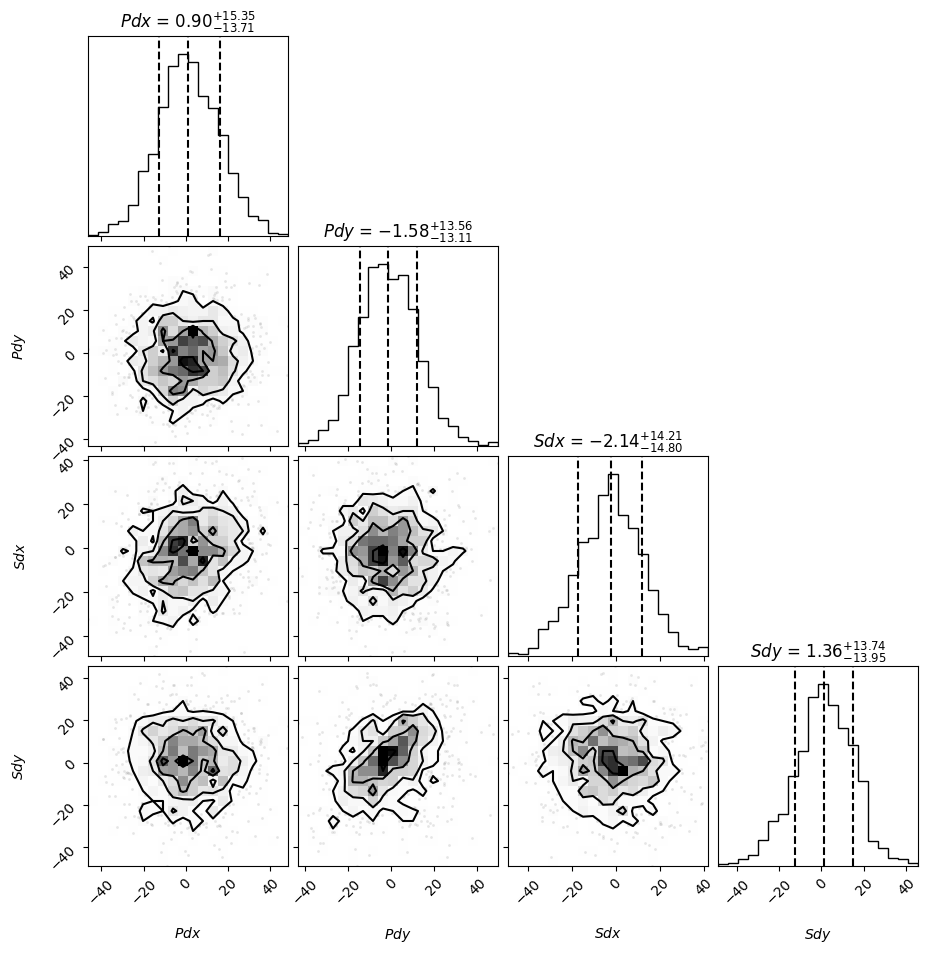

In [ ]:
figure = corner.corner(
    np.array(dps),
    labels=[
        r"$Pdx$",
        r"$Pdy$",
        r"$Sdx$",
        r"$Sdy$",
    ],
    quantiles=[0.02, 0.5, 0.98],
    show_titles=True,
    title_kwargs={"fontsize": 12},
)

In [37]:
x1.shape

(1499,)